Using device: cpu

Training BiRNN...
Epoch 10/50 - Loss: 0.00203
Epoch 20/50 - Loss: 0.00256
Epoch 30/50 - Loss: 0.00201
Epoch 40/50 - Loss: 0.00177
Epoch 50/50 - Loss: 0.00238

Training Feedforward Neural Network...
Epoch 10/50 - Loss: 0.00480
Epoch 20/50 - Loss: 0.00278
Epoch 30/50 - Loss: 0.00226
Epoch 40/50 - Loss: 0.00205
Epoch 50/50 - Loss: 0.00189

Results
-----------------------------
BiRNN MSE       : 1707.09
Feedforward MSE : 1452.24


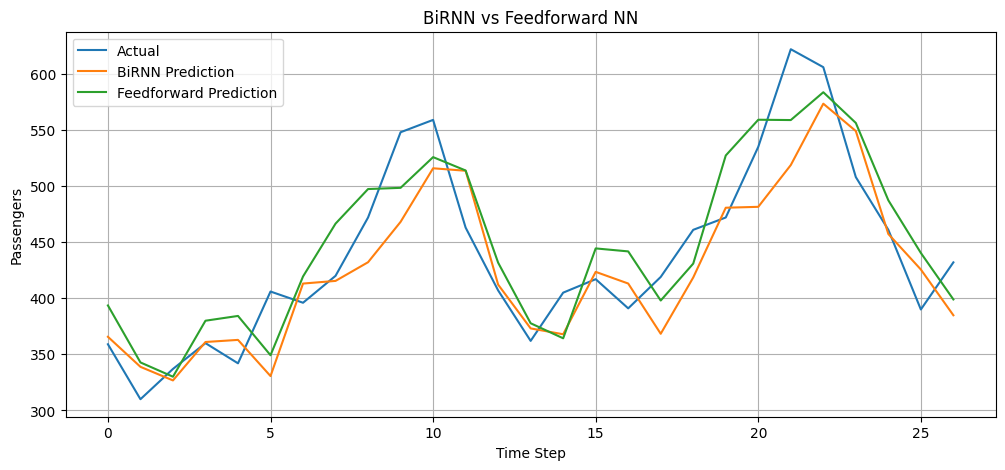

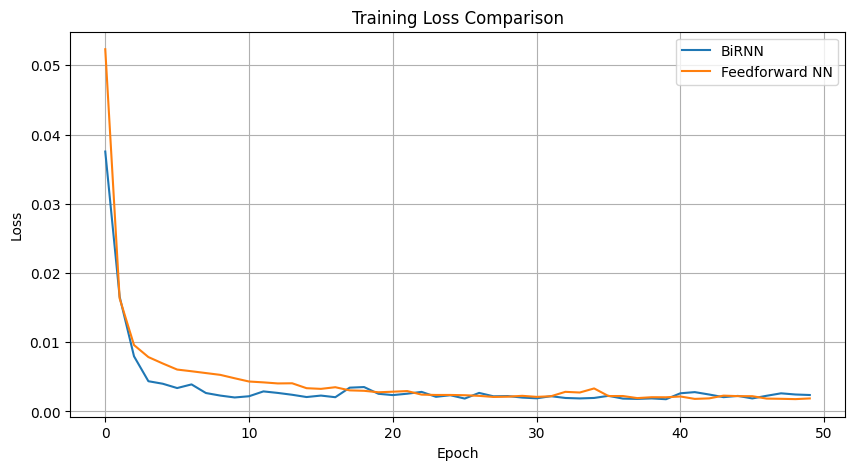

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
from torch.utils.data import TensorDataset, DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

url = "https://raw.githubusercontent.com/jbrownlee/Datasets/refs/heads/master/monthly-airline-passengers.csv"

df = pd.read_csv(url)

data = df.iloc[:, 1].values.astype("float32").reshape(-1, 1)

scaler = MinMaxScaler()
data_scaled = scaler.fit_transform(data)

SEQ_LENGTH = 10

X = []
y = []

for i in range(len(data_scaled) - SEQ_LENGTH):
    X.append(data_scaled[i:i + SEQ_LENGTH])
    y.append(data_scaled[i + SEQ_LENGTH])

X = np.array(X)
y = np.array(y)

train_size = int(len(X) * 0.8)

X_train = X[:train_size]
X_test = X[train_size:]

y_train = y[:train_size]
y_test = y[train_size:]


X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32)

X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32)

train_loader = DataLoader(
    TensorDataset(X_train_tensor, y_train_tensor),
    batch_size=16,
    shuffle=True
)

class BiRNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.rnn = nn.RNN(
            input_size=1,
            hidden_size=32,
            batch_first=True,
            bidirectional=True
        )

        self.fc = nn.Linear(64, 1)

    def forward(self, x):

        out, _ = self.rnn(x)

        return self.fc(out[:, -1, :])


class FeedforwardNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.fc1 = nn.Linear(SEQ_LENGTH, 32)
        self.fc2 = nn.Linear(32, 1)

    def forward(self, x):

        x = x.view(x.size(0), -1)

        x = torch.relu(self.fc1(x))

        return self.fc2(x)


def train_model(model, epochs=50):

    model = model.to(device)

    criterion = nn.MSELoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.01
    )

    losses = []

    for epoch in range(epochs):

        model.train()

        total_loss = 0

        for sequences, targets in train_loader:

            sequences = sequences.to(device)
            targets = targets.to(device)

            optimizer.zero_grad()

            outputs = model(sequences)

            loss = criterion(outputs, targets)

            loss.backward()

            optimizer.step()

            total_loss += loss.item()

        avg_loss = total_loss / len(train_loader)

        losses.append(avg_loss)

        if (epoch + 1) % 10 == 0:
            print(
                f"Epoch {epoch+1}/{epochs} - Loss: {avg_loss:.5f}"
            )

    return model, losses


print("\nTraining BiRNN...")

birnn = BiRNN()

birnn, birnn_losses = train_model(birnn)

print("\nTraining Feedforward Neural Network...")

ffnn = FeedforwardNN()

ffnn, ffnn_losses = train_model(ffnn)


birnn.eval()
ffnn.eval()

with torch.no_grad():

    X_test_device = X_test_tensor.to(device)

    pred_birnn = birnn(X_test_device).cpu().numpy()

    pred_ffnn = ffnn(X_test_device).cpu().numpy()


# Inverse transform
pred_birnn = scaler.inverse_transform(pred_birnn)

pred_ffnn = scaler.inverse_transform(pred_ffnn)

actual = scaler.inverse_transform(y_test)


# Calculate MSE
mse_birnn = mean_squared_error(actual, pred_birnn)

mse_ffnn = mean_squared_error(actual, pred_ffnn)

print("\nResults")
print("-----------------------------")
print(f"BiRNN MSE       : {mse_birnn:.2f}")
print(f"Feedforward MSE : {mse_ffnn:.2f}")


# Plot predictions
plt.figure(figsize=(12, 5))

plt.plot(actual, label="Actual")

plt.plot(
    pred_birnn,
    label="BiRNN Prediction"
)

plt.plot(
    pred_ffnn,
    label="Feedforward Prediction"
)

plt.title("BiRNN vs Feedforward NN")

plt.xlabel("Time Step")

plt.ylabel("Passengers")

plt.legend()

plt.grid()

plt.show()


plt.figure(figsize=(10, 5))

plt.plot(
    birnn_losses,
    label="BiRNN"
)

plt.plot(
    ffnn_losses,
    label="Feedforward NN"
)

plt.title("Training Loss Comparison")

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.legend()

plt.grid()

plt.show()